Epoch 1/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.2999 - loss: 1.9356 - val_accuracy: 0.3085 - val_loss: 1.8535
Epoch 2/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.3700 - loss: 1.7550 - val_accuracy: 0.3719 - val_loss: 1.7466
Epoch 3/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.3964 - loss: 1.6844 - val_accuracy: 0.3880 - val_loss: 1.7064
Epoch 4/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.4136 - loss: 1.6370 - val_accuracy: 0.3960 - val_loss: 1.7027
Epoch 5/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.4249 - loss: 1.6026 - val_accuracy: 0.4200 - val_loss: 1.6237
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4156 - loss: 1.6125
Test Accuracy: 41.56000018119812 %
Test Loss: 1.6125237941741943


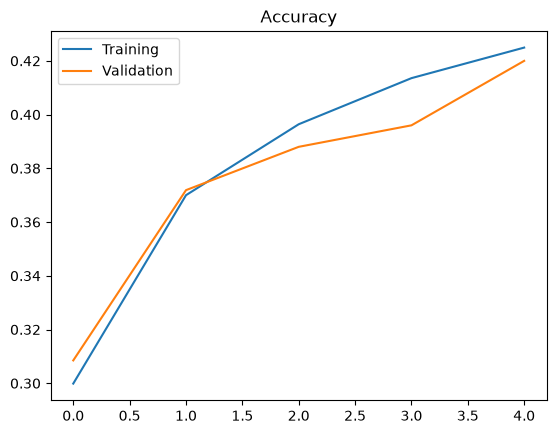

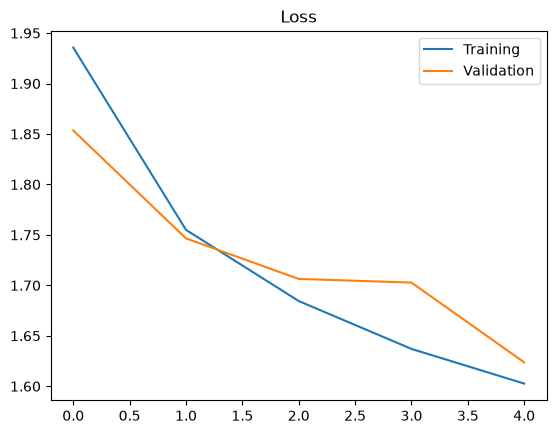

In [8]:
# 1. Import libraries
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# 2. Load CIFAR-10 dataset
data = pd.read_csv("cifar-10.csv")

# 3. Separate images and labels
X = data.drop("label", axis=1).values
y = data["label"].values

# 4. Normalize pixel values
X = X / 255.0

# 5. Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 6. Create FNN model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(3072,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# 7. Compile model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# 8. Train model
history = model.fit(X_train, y_train,
                    epochs=5,
                    batch_size=32,
                    validation_split=0.2)

# 9. Evaluate model
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", accuracy * 100, "%")
print("Test Loss:", loss)

# 10. Plot accuracy and loss
plt.Figure()
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Accuracy")
plt.legend(["Training", "Validation"])
plt.show()


plt.Figure()
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Loss")
plt.legend(["Training", "Validation"])

plt.show()

In [ ]:
# Practical 1C – Feedforward Neural Network (FNN) for CIFAR-10 Image Classification



Difficulty: Medium

Deep Learning – ANN / FNN



Let's prepare this practical from zero, just like Practical 1A. I'll explain the basic concepts, every code line, the working of the model, and the questions your examiner might ask.

First, understand the difference between Practical 1A and 1C.

| Practical 1A       | Practical 1C             |
| ------------------ | ------------------------ |
| MNIST dataset      | CIFAR-10 dataset         |
| Handwritten digits | Real-world object images |
| 28 × 28 pixels     | 32 × 32 pixels           |
| Grayscale images   | RGB colour images        |
| 784 input features | 3072 input features      |
| 10 classes         | 10 classes               |

The main concept is the same: we use an FNN to classify images. But CIFAR-10 is more challenging because it contains coloured images of real-world objects.

## 1. What is CIFAR-10?

CIFAR-10 is a popular image dataset used for training and testing image classification models.

It contains 60,000 colour images divided into 10 different categories.

[Khan Academy](https://images.openai.com/static-rsc-4/KsLVGWO_kpQvMLwmTyCkvn-D82brrwm_qjWfPk5ngAzTjmsnmbZCvdTnN2S9U5i-KRydXTZvhpA1GW8IP-UR0bRDtJnLoCOmFjIsKXQ9PVzIpL7iNJAZODA96CGoAVzFZcKrKecy3IS3pzi4PBCZauUL33lDVrw3J7eO7pWY0ag?purpose=inline)

Airplane

[21 Best AI Image Recognition Machine Learning Projects (2025)](https://images.openai.com/static-rsc-4/PW-1qz-YBQ_IkfdrnU-Kqqwkpub3oAKJzv4gbpuuQL8JgKZ7gPVl6uaA_usV18q9szwlmYBD68LZSjDEJ8qXX62M7kr2aFswG76Bmpka5MLWY-YyvVLZkP79_KnSGYN6249WBkx5rFl3efB3-FP0A_N-S8VgTTK2341HGCPS4nE?purpose=inline)

Automobile

Bird

[Out-of-Distribution (OOD) Detection Based on Deep Learning: A Review | MDPI](https://images.openai.com/static-rsc-4/gBakWDVwfCqVDQcHmzUydOQtOO2uSX395l1dxe3RUrWJL8WWmcg5-yq7whOpjPe60v5YWXpu-S16R-LZd-G-E4Sa7_9JI0ZqHWt0Kj96YIiRRyxIG4OBnBoB9xa2Wgh6SegxVOwhzdCBnZtQsEavaPadq9NkfgX8-Zr1MqEosmE?purpose=inline)

Cat

[Building Custom Image Datasets in PyTorch: Tutorial with Code – Glass Box Medicine](https://images.openai.com/static-rsc-4/VQyk95W4_jzxNbZN2EhjyL8PiWvclTHeDM3cUhBwa3QN2RtwYV5IPcRj1MczqtZZOjAAEms1fKSDpWCeSSAU_S_sQb5fZFYfsP-_VTJusaxe6jcnU-VUciDEee5ihOrDPXahRUqqifay7saKee-qW6TZ54wP12oqt2qbKiuNu9I?purpose=inline)

Deer

[PyTorch学习笔记——CIFAR10图像数据模型训练及验证(CNN)\_cifar10模型-CSDN博客](https://images.openai.com/static-rsc-4/Vx_1CuP9Q8pV-i2ceKidCUMxRmbpCgP7qt7qvbNUJKSRcb8Fj-F8PdyYp6u_8TDeAbLZl_AK5PefM_a0ijJQgYnFp2pmoqBKuxtGsXP-0pQyQ0I_BqzEhJzTUityMX3Upfv9vyAtY3jmfFd56FwFPx5lLL0vRkzI3wGunwOg9MQ?purpose=inline)

Dog

[How to Build a Simple Image Recognition System with TensorFlow (Part 1) – Wolfgang Beyer – Personal Blog](https://images.openai.com/static-rsc-4/Hap0tkJwOvq5zBb-aHKBPHPlNzPJSLGevFR6bIpoAGjOLydxa7kCUTnMskiCdxLTdJQT86TKTg6FAt9ghsh7q8ItLJUI-53DsfqPlxRzdpQkWrmd4TMIx98HUIbsJVrZOFJwxi3M7tvfprwHIkJ4xOAZOfgKEfEPaftdaaRcevo?purpose=inline)

Frog

[Image Classification using Tensorflow2.0 on CIFAR-10 dataset | by Namratesh Shrivastav | Analytics Vidhya | Medium](https://images.openai.com/static-rsc-4/2BweRP-mcHQkio1Xllibd2-qaB5IlklXibqMPXkSMPufnhUKvJHNJtu8mbVO8wosLZVDo-NYv5BHslDmM1H5-w7mAfE4lwqjU2mgEuFNc6owPNy9nLo1BxQrFqoXPyFlh3clV4K6QJIgNJXt4Yb5PNK82NUfB93QDho3UzGVrPU?purpose=inline)

Horse

[CS440 Lectures](https://images.openai.com/static-rsc-4/RDON2paeIG6r-gqueJ_AKWN9f3_kdw9owP1M6w-pJJWKDPrcqCp5SX6qFk4LMIKo7K2ktSAopd5FQyauqxR0Aq-e30A4L0vqGtEtKqbgG3_53SWPB5oIyN-0i4S6ZWoccI1lwTLx_Yd-RTGzGu9sfD7c0IwHyfzbCvOKg6mUPXg?purpose=inline)

Ship

[【技术综述】你真的了解图像分类吗？-腾讯云开发者社区-腾讯云](https://images.openai.com/static-rsc-4/uJfYe05AdRtdi-fbWj8mgnOyp0X6kf2E4GqRkaAg_N3il_qA74Cq2IZLZdftaVWjD7aF_gxLR4VOygeTp7epSv8jPgetcuzFVhPcbrPgt8bv-z8StDlMWMMzK4Z-4R95jgNEngxJtu2EskE_teZlj_49gwRGJInoC8kv_HUBdug?purpose=inline)

Truck

### Important facts about CIFAR-10

| Property                            | Value   |
| ----------------------------------- | ------- |
| Total images                        | 60,000  |
| Training images in original dataset | 50,000  |
| Testing images in original dataset  | 10,000  |
| Image dimensions                    | 32 × 32 |
| Image channels                      | 3 (RGB) |
| Classes                             | 10      |
| Image type                          | Colour  |

### What is RGB?

RGB stands for:

- R = Red
- G = Green
- B = Blue

A colour image has three channels instead of one grayscale channel.

Each channel contains 32 × 32 pixel values.

Therefore:

\\[ 32 \times 32 \times 3 = 3072 \\]

This is why our input layer contains 3072 features.

Remember this calculation. Your examiner can ask it directly.

## 2. Understand the overall working

Our practical follows this process:

CIFAR-10 CSV Dataset

Images + Labels

Preprocessing

Separate X and Y + Normalize

Train-Test Split

80% Training + 20% Testing

FNN Model

3072 → 128 → 64 → 10

Training using Adam

5 Epochs, Batch Size 32

Evaluation and Graphs

Test Accuracy + Test Loss

## 3. Code explanation – Step by step

### Step 1: Import libraries

```
import pandas as pdimport tensorflow as tfimport matplotlib.pyplot as pltfrom sklearn.model_selection import train_test_split
```

We import four libraries.

| Library      | Purpose                                 |
| ------------ | --------------------------------------- |
| Pandas       | Load and handle CSV dataset             |
| TensorFlow   | Build and train neural network          |
| Matplotlib   | Plot graphs                             |
| Scikit-learn | Split dataset into training and testing |

New concept: Scikit-learn

Scikit-learn is a Python machine learning library.

We use its `train_test_split()` function to divide our dataset into training and testing parts.

Viva:

Q. Why do we use Scikit-learn?

To perform machine learning operations such as splitting data into training and testing sets.

### Step 2: Load CIFAR-10 dataset

```
data = pd.read_csv("cifar-10.csv")
```

Here, we load the CSV dataset using Pandas.

Your dataset should contain:

- One `label` column.
- 3072 pixel columns.

For example:

| label | pixel1 | pixel2 | pixel3 | ... |
| ----- | ------ | ------ | ------ | --- |
| 0     | 120    | 45     | 90     | ... |
| 1     | 200    | 100    | 50     | ... |
| 2     | 80     | 60     | 30     | ... |

Important: Your code assumes that the CSV has a column named `label`, and labels are integers from 0 to 9.

### Step 3: Separate images and labels

```
X = data.drop("label", axis=1).valuesy = data["label"].values
```

We separate the dataset into input and output.

- `X` contains image pixel values.
- `y` contains the actual image labels.

For example:

```
X = [120, 45, 90, 200, ...]y = 0
```

Here, 0 represents the airplane class in the standard CIFAR-10 label mapping.

The standard CIFAR-10 labels are:

| Label | Class      |
| ----- | ---------- |
| 0     | Airplane   |
| 1     | Automobile |
| 2     | Bird       |
| 3     | Cat        |
| 4     | Deer       |
| 5     | Dog        |
| 6     | Frog       |
| 7     | Horse      |
| 8     | Ship       |
| 9     | Truck      |

Examiner question: Why do we separate X and y?

Because X contains the input features, while y contains the correct answers that the model needs to learn.

### Step 4: Normalize pixel values

```
X = X / 255.0
```

The original pixel values are between 0 and 255.

We divide them by 255 to convert them into values between 0 and 1.

For example:

| Original pixel | Normalized pixel |
| -------------- | ---------------- |
| 0              | 0.0              |
| 100            | 0.392            |
| 200            | 0.784            |
| 255            | 1.0              |

Why normalize?

It helps the neural network train more efficiently and keeps input values in a consistent range.

This is the same concept you learned in Practical 1A.

### Step 5: Split the dataset

```
X_train, X_test, y_train, y_test = train_test_split(    X, y, test_size=0.2, random_state=42)
```

This is a very important new concept.

We divide our dataset into two parts:

- Training data: 80%
- Testing data: 20%

Understand the parameters:

1\. `X, y`

These are our input images and their labels.

2\. `test_size=0.2`

This means 20% of the dataset is reserved for testing.

For example, if we have 10,000 images:

- 8,000 training images.
- 2,000 testing images.

3\. `random_state=42`

This ensures that the dataset is split in the same way whenever we run the code with the same input data.

42 is just a chosen seed value. It has no special mathematical importance.

Example: 10,000 images

80% Training

20% Testing

Viva questions:

- What is train-test splitting?
- What is the purpose of test_size?
- What is random_state?
- Why do we keep testing data separate?

Answers: It separates data for learning and evaluation; `test_size=0.2` reserves 20% for testing; `random_state` makes the split reproducible; separate test data helps measure performance on unseen examples.

### Step 6: Create the FNN model

Your code:

```
model = tf.keras.Sequential([    tf.keras.layers.Input(shape=(3072,)),    tf.keras.layers.Dense(128, activation='relu'),    tf.keras.layers.Dense(64, activation='relu'),    tf.keras.layers.Dense(10, activation='softmax')])
```

Very important for viva

Here we are creating the architecture of our neural network.

First, understand the architecture:

## CIFAR-10 FNN Architecture

Input Layer

# 3072

32 × 32 × 3 pixels

Hidden Layer 1

# 128

Neurons – ReLU

Hidden Layer 2

# 64

Neurons – ReLU

Output Layer

# 10

Neurons – Softmax

Predicted Class

Airplane / Car / Bird / Cat / ...

Let's understand each line.

1\. Input layer

```
tf.keras.layers.Input(shape=(3072,))
```

This tells the model that each input image contains 3072 features.

Why 3072?

\\[ 32 \times 32 \times 3 = 3072 \\]

Because each CIFAR-10 image contains:

- 32 pixels in height.
- 32 pixels in width.
- 3 colour channels (RGB).

Why is there no Flatten layer here?

This is an important difference from Practical 1A.

In Practical 1A, the input was a 28 × 28 image, and we used Flatten to convert it into 784 values.

Here, our CSV already contains each image as a row of 3072 pixel values.

Therefore, we don't need Flatten.

2\. First hidden layer

```
tf.keras.layers.Dense(128, activation='relu')
```

This creates a fully connected layer containing 128 neurons.

- Dense = Fully connected layer.
- 128 = Number of neurons.
- ReLU = Activation function.

The neurons learn different patterns from the input image data.

3\. Second hidden layer

```
tf.keras.layers.Dense(64, activation='relu')
```

This creates another hidden layer containing 64 neurons.

Why another hidden layer?

The first layer learns some patterns, and the next layer can learn more complex combinations of those patterns.

4\. Output layer

```
tf.keras.layers.Dense(10, activation='softmax')
```

We use 10 neurons because CIFAR-10 has 10 classes.

Softmax converts the output values into probabilities.

For example:

| Class      | Probability |
| ---------- | ----------- |
| Airplane   | 0.05        |
| Automobile | 0.02        |
| Bird       | 0.03        |
| Cat        | 0.10        |
| Deer       | 0.05        |
| Dog        | 0.65        |
| Frog       | 0.02        |
| Horse      | 0.03        |
| Ship       | 0.03        |
| Truck      | 0.02        |

The highest probability is 0.65, so the predicted class is Dog.

Important viva question:

Q. Why do we use two hidden layers?

Answer: We use two hidden layers so that the network can learn different levels of patterns and more complex relationships from the image data.

Q. Can we use more neurons?

Yes. We can change the number of neurons depending on the problem and model performance.

### Step 7: Compile the model

Your code:

```
model.compile(optimizer='adam',              loss='sparse_categorical_crossentropy',              metrics=['accuracy'])
```

Before training, we configure the model.

There are three important parameters.

1\. Optimizer – Adam

```
optimizer='adam'
```

Adam stands for Adaptive Moment Estimation.

It is an optimization algorithm used to update the weights of a neural network and reduce loss.

You may remember SGD from Practical 1A.

Now we are using Adam.

Difference between SGD and Adam:

| SGD                                    | Adam                                           |
| -------------------------------------- | ---------------------------------------------- |
| Stochastic Gradient Descent            | Adaptive Moment Estimation                     |
| Basic optimization algorithm           | More adaptive optimization algorithm           |
| Uses a learning rate to update weights | Adapts effective learning rates for parameters |
| Can require more tuning                | Often works well with default settings         |

Why Adam?

Adam automatically adapts the learning rate for different parameters and often provides faster or more convenient training.

The question says SGD/Adam, so either can be used if implemented correctly.

2\. Loss function

```
loss='sparse_categorical_crossentropy'
```

This measures the difference between the actual class and predicted class.

Why sparse categorical crossentropy?

Because our labels are integer values between 0 and 9.

For example:

```
y = [0, 1, 2, 3, 4, 5]
```

We don't need to convert these labels into one-hot encoding.

3\. Accuracy

```
metrics=['accuracy']
```

This calculates how many images are classified correctly.

For example:

If 800 out of 1,000 images are classified correctly:

\\[ Accuracy=\frac{800}{1000}\times100=80\\% \\]

Viva questions:

Q. What is Adam?

Adam is an optimization algorithm that adapts learning rates while updating the neural network weights.

Q. Which optimizer is used in your practical?

Adam.

Q. Can we use SGD instead?

Yes. We can replace `optimizer='adam'` with `optimizer='sgd'`.

Q. Why do we use sparse categorical crossentropy?

Because we have 10 classes and integer-encoded labels.

### Step 8: Train the model

Your code:

```
history = model.fit(X_train, y_train,                    epochs=5,                    batch_size=32,                    validation_split=0.2)
```

This is where the model actually learns from the training dataset.

Let's understand each parameter.

1\. `X_train`

Contains training images.

2\. `y_train`

Contains the correct class labels.

3\. `epochs=5`

The model goes through the complete training portion five times.

One epoch means one complete pass through the training dataset.

Why 5 epochs?

Because we have selected 5 training cycles for this practical.

4\. `batch_size=32`

This is a new and important concept.

Batch size means the number of training images processed together before updating the model's weights.

Here, the model processes 32 images at a time.

For example, if we have 8,000 training images:

\\[ \text{Batches}=\frac{8000}{32}=250 \\]

So, one epoch has 250 batches.

After processing each batch, the model updates its weights.

5\. `validation_split=0.2`

This means 20% of the training data is reserved for validation.

What is validation data?

Validation data is used to check how well the model is performing during training.

It helps us observe whether the model is learning properly or overfitting.

Let's understand the difference:

| Training        | Validation               | Testing                   |
| --------------- | ------------------------ | ------------------------- |
| Used to learn   | Used to monitor learning | Used for final evaluation |
| Updates weights | Does not update weights  | Does not update weights   |
| Used in `fit()` | Used in `fit()`          | Used in `evaluate()`      |

Important calculation for your practical:

Suppose your original CSV contains 60,000 images.

After 80:20 splitting:

- Training portion = 48,000
- Testing portion = 12,000

Then `validation_split=0.2` takes 20% of the 48,000 training images:

- Actual training = 38,400
- Validation = 9,600
- Testing = 12,000

Data distribution in this example

64% Training

16% Validation

20% Testing

Viva questions:

Q. What is batch size?

The number of training samples processed together before updating model weights.

Q. What is validation data?

Data used to monitor model performance during training.

Q. What is the difference between validation and testing?

Validation monitors the model during training, while testing measures its final performance on unseen data.

Q. What is the batch size in your code?

Q. How many epochs are used?

5 epochs.

### Step 9: Evaluate the model

Your code:

```
loss, accuracy = model.evaluate(X_test, y_test)print("Test Accuracy:", accuracy * 100, "%")print("Test Loss:", loss)
```

After training, we evaluate the model using testing data.

`model.evaluate()` returns two values:

1. Test loss.
2. Test accuracy.

For example:

```
Test Accuracy: 48.5 %
Test Loss: 1.45
```

These are only example values, not guaranteed results.

What does test accuracy mean?

It tells us the percentage of test images that the model classified correctly.

What does test loss mean?

It measures how wrong the model's predictions are on the testing dataset.

Remember:

- Lower loss is generally better.
- Higher accuracy is generally better.

### Step 10: Plot accuracy and loss

Your code:

```
plt.Figure()plt.plot(history.history['accuracy'])plt.plot(history.history['val_accuracy'])plt.title("Accuracy")plt.legend(["Training", "Validation"])plt.show()
```

Let's understand this.

1\. `history.history['accuracy']`

Stores the training accuracy for every epoch.

2\. `history.history['val_accuracy']`

Stores the validation accuracy for every epoch.

3\. `plt.title("Accuracy")`

Sets the graph title.

4\. `plt.legend()`

Displays the names of the two lines.

5\. `plt.show()`

Displays the graph.

Now the loss graph:

```
plt.Figure()plt.plot(history.history['loss'])plt.plot(history.history['val_loss'])plt.title("Loss")plt.legend(["Training", "Validation"])plt.show()
```

Here:

- `loss` = Training loss.
- `val_loss` = Validation loss.

### How to understand these graphs?

[TorchAO Quantization Overview. Quantization involves converting a… | by Gereziher Adhane | Medium](https://images.openai.com/static-rsc-4/7tI_bRp6dxP2URiWcvpiRTBfVctzOAzv-vheEG0y4gEd-pm8NE2wwzUinADbaVmoeqVKXf_5gj-0BrOydk6_xk-IdmUkdC8BRAQ0e7ano6JRm27oBQsLkyqbiQIuBUNtotugndCCHZvAWR3miCj2gsN65MoETcbAJkQ8aj9n8BQ?purpose=inline)

Accuracy graph

Generally, accuracy should increase.

[Gastroenterological disease detection using transformer-based medical imaging for sustainable healthcare | Scientific Reports](https://images.openai.com/static-rsc-4/OwtqFj2jX8y9kGM9yU5FHuK-5EWrwQXuH8LIbXkJMJZUlcG3mOJ4XCD6BwmzJm1aHgZHmfXQeXi7XkZW8WVOB3QPXdCdqdaB1E6rkJx-E9yR10WoMJALrsyXxFjq5jLQlQ4kJ_RHwyTJC-AF_UOjQl0wxvZHytCvjTVHmxc0VBw?purpose=inline)

Loss graph

Generally, loss should decrease.

Important: Your code has a small mistake.

You wrote:

```
plt.Figure()
```

It should be:

```
plt.figure()
```

Python is case-sensitive. `figure()` is the Matplotlib function used to create a new figure.

Also, I recommend adding axis labels:

```
plt.figure()plt.plot(history.history['accuracy'])plt.plot(history.history['val_accuracy'])plt.title("Accuracy")plt.xlabel("Epochs")plt.ylabel("Accuracy")plt.legend(["Training", "Validation"])plt.show()
```

Viva questions:

Q. What is validation accuracy?

It is the accuracy measured on the validation dataset after each epoch.

Q. What is validation loss?

It is the loss measured on the validation dataset after each epoch.

Q. Why do we plot two lines?

To compare the model's performance on training data and validation data.

Q. What is overfitting?

When training performance is very good but validation or testing performance is poor.

## 4. Important concepts the examiner may ask

### A. Why is CIFAR-10 more difficult than MNIST?

- MNIST contains simple handwritten digits.
- CIFAR-10 contains real-world colour images.
- CIFAR-10 has more complex shapes, backgrounds and object variations.
- Therefore, classifying CIFAR-10 is generally more difficult.

### B. Why is FNN not the best model for CIFAR-10?

This is a particularly good viva question.

FNN converts images into one-dimensional arrays.

When we flatten an image, we lose its direct two-dimensional spatial arrangement.

For example, a CNN can identify nearby pixels and learn spatial features such as edges, shapes and patterns using convolution filters.

An FNN does not explicitly preserve this spatial structure.

Therefore, CNNs are generally more effective for image classification tasks such as CIFAR-10.

### C. What is the difference between an FNN and a CNN?

| FNN                                            | CNN                                 |
| ---------------------------------------------- | ----------------------------------- |
| Fully connected layers                         | Convolutional layers                |
| Input is commonly flattened                    | Can process 2D images directly      |
| Does not explicitly preserve spatial structure | Learns spatial features             |
| Simpler image architecture                     | More suitable for image recognition |

### D. What is backpropagation?

Backpropagation is the process through which a neural network calculates gradients of the loss with respect to its weights, moving backward through the network.

The optimizer uses these gradients to update the weights and reduce the loss.

### E. What is a learning rate?

The learning rate controls how much the model changes its weights during each update.

If it is too high, training can become unstable. If it is too low, training may be very slow.

### F. What is a parameter?

Parameters are the values learned by the neural network, mainly weights and biases.

Your model learns these values during training.

## 5. Most expected viva questions

These are additional questions worth preparing.

| No. | Question                            | Answer                                                                                               |
| --- | ----------------------------------- | ---------------------------------------------------------------------------------------------------- |
| 1   | What is CIFAR-10?                   | A dataset containing 60,000 colour images belonging to 10 classes.                                   |
| 2   | What does CIFAR stand for?          | Canadian Institute for Advanced Research.                                                            |
| 3   | What is RGB?                        | Red, Green and Blue.                                                                                 |
| 4   | What is the image size?             | 32 × 32 pixels.                                                                                      |
| 5   | Why are there 3072 input features?  | 32 × 32 × 3 = 3072.                                                                                  |
| 6   | How many output neurons are used?   | 10.                                                                                                  |
| 7   | Which optimizer did you use?        | Adam.                                                                                                |
| 8   | What is Adam's full form?           | Adaptive Moment Estimation.                                                                          |
| 9   | What is batch size?                 | Number of samples processed together before updating weights.                                        |
| 10  | What is an epoch?                   | One complete pass through the training dataset.                                                      |
| 11  | How many epochs did you use?        | 5.                                                                                                   |
| 12  | What is validation split?           | The fraction of training data reserved for validation.                                               |
| 13  | What is Softmax?                    | An activation function that converts outputs into probabilities.                                     |
| 14  | What is ReLU?                       | An activation function that returns zero for negative inputs and the same value for positive inputs. |
| 15  | What is classification?             | Assigning an input to one of the predefined categories.                                              |
| 16  | What is normalization?              | Scaling values into a smaller consistent range.                                                      |
| 17  | What is overfitting?                | When a model learns training data too specifically and performs poorly on unseen data.               |
| 18  | Which library is used for graphs?   | Matplotlib.                                                                                          |
| 19  | Which function trains the model?    | `model.fit()`.                                                                                       |
| 20  | Which function evaluates the model? | `model.evaluate()`.                                                                                  |

## 6. Important corrections and things to remember in your code

There are three things I want you to understand before your practical exam.

1\. Your CSV dataset must have the correct structure.

Your code expects:

- One column named `label`.
- Exactly 3072 pixel columns.
- Labels encoded as integers 0–9.
- Pixel columns containing the RGB values in a consistent image order.

Also, the standard label mapping must be correct if you want the predicted class names to match CIFAR-10.

2\. Your graph code

Replace both occurrences of:

```
plt.Figure()
```

with:

```
plt.figure()
```

3\. FNN accuracy

Do not expect FNN to achieve the same accuracy as a CNN on CIFAR-10. FNN is a basic approach for image classification, and it does not explicitly learn spatial relationships between neighbouring pixels.

## 7. How to explain this practical in front of the examiner

If the examiner says, "Explain your practical," you can speak this:

Ready-to-speak viva explanation

"In this practical, I have implemented a Feedforward Neural Network using TensorFlow and Keras for CIFAR-10 image classification.

CIFAR-10 is a dataset containing 60,000 colour images divided into 10 different classes, such as airplanes, cars, birds and cats.

First, I imported the required libraries and loaded my dataset from a CSV file.

Then, I separated the input images and their corresponding labels and normalized the pixel values by dividing them by 255.

After that, I divided the dataset into 80% training and 20% testing data.

I created an FNN using Keras Sequential with an input size of 3072, two hidden layers containing 128 and 64 neurons using ReLU activation, and an output layer containing 10 neurons using Softmax activation.

I compiled the model using the Adam optimizer, sparse categorical crossentropy loss and accuracy metric.

Then, I trained the model for 5 epochs with a batch size of 32 and used 20% of the training data for validation.

Finally, I evaluated the model using testing data and plotted training and validation accuracy and loss using Matplotlib."

&#x20;Copy explanation

## 8. Test your understanding – Viva mock test

Mock viva – 5 questions

0/5 answered

1\. Why does CIFAR-10 have 3072 input features?

32 × 32 × 3

28 × 28

64 × 64

2\. What is the purpose of batch_size=32?

Train for 32 epochs

Process 32 images together before a weight update

Use 32 output classes

3\. What is the purpose of validation_split=0.2?

20% testing data

20% training accuracy

20% of training data for validation

4\. Which optimizer is used in your code?

SGD

Adam

ReLU

5\. Why is CNN generally better than FNN for images?

CNN learns spatial features

FNN always has more neurons

CNN does not require training

Submit viva answers

My recommendation: The most important difference to understand between 1A and 1C is the input size (784 vs 3072), image type (grayscale vs RGB), and the additional hidden layer in 1C.

Once you understand these differences, a large portion of the viva becomes much easier.